# Checking the outer gradient w.r.t. `geoms`

Final check of the outer bilevel objective's gradient w.r.t. `geoms`: compares the Zygote
derivative of `Λ_dot_dFdo_distributed` (the `geoms` block of `outer_gradient_distributed`) against
a naive finite difference of the true outer objective
`F(geoms) = ||Tmap - Tmap_opt(geoms)||^2/||Tmap||^2 + ||zmap - zmap_opt(geoms)||^2/||zmap||^2`,
evaluated along a random direction `v` -- the same test as `2026-09-23-develop-pipeling.ipynb`'s
"Naive finite-difference check of `grad` against the outer bilevel objective" section, re-run on
the current codebase (this notebook is on `features/active-variables-T`, so the adjoint/Hessian
machinery below goes through `get_free_and_active_indices`, not the older z-only
`get_active_variables(zmap, imghp)` the 09-23 notebook used).

Same `php`/`imghp` as `2026-10-20-tune-regularization.ipynb` (`UniformlyRandomObject`, but 2%
relative noise here, not 20%), except literal `rechp.α_init = rechp.β_init = 1e-7` (not `:auto` --
this notebook isn't about tuning those, just checking the gradient at a fixed, reasonable
operating point). `geoms` here is randomly generated directly in this notebook (not loaded via
`opthp.geoms_init_type`), deliberately kept well inside `[pillar_width_lb, pillar_width_ub]` so
that no perturbation in the finite-difference sweep below ever needs to clamp back into bounds --
a loaded monochromatic-lens design routinely sits at or very close to those bounds, which would
make `objective_function` non-smooth exactly where it's being differenced.

In [1]:
cd("../../End2EndThermalImg")
import Pkg
Pkg.activate(".")

  Activating project at `~/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg`


In [21]:
using Revise
using End2EndThermalImg
using PythonPlot
using Parameters
using Distributed
using LinearAlgebra
using IterativeSolvers
using Statistics
using Zygote

## Setup

In [3]:
@time nw = End2EndThermalImg.setup_cluster_workers()
println("nworkers = ", nworkers(), "  workers = ", workers())
println("threads per worker = ", [remotecall_fetch(Threads.nthreads, p) for p in workers()])

      From worker 5:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 5:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 6:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 6:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 3:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 3:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 4:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 4:	└   lock_file = "/Us

In [4]:
# Same hyperparameters as 2026-10-20-tune-regularization.ipynb, except 2% relative noise (not
# 20%) and literal α_init/β_init (not :auto). opthp.geoms_init_type is unused here -- geoms is
# generated directly below, not via initialize_geoms -- so its value doesn't matter.
@time @everywhere begin
    php = PhysicsHyperParams(
        λlb_μm = 8.0,
        λub_μm = 12.0,
        freq_order = 20,
        focal_length_μm = 2.0e4,
        num_unit_cells = 2048,
        unit_cell_length_μm = 4.0,
        pillar_width_lb_μm = 1.8,
        pillar_width_ub_μm = 2.7,
        pillar_width_order = 160,
        pillar_height_μm = 10.0,
        pillar_material = "Si_no_absorption",
        substrate_height_μm = 300.0,
        substrate_material = "Si_no_absorption",
        nG = 1000
    )

    imghp = ImagingHyperParams(
        objN = 32,
        imgN = 128,
        binN = 3,
        sampleN = 1,
        PSF_zlb_μm = -2.1e6,
        PSF_zub_μm = -0.9e6,
        PSF_zlen = 3,
        smoothness_order = 3.0,
        object_type = UniformlyRandomObject(Tlb = 136.15, Tub = 450.15, zlb_μm = -2.0e6, zub_μm = -1.0e6, zlen = 7, php = php),
        noise_type = RelativeNoise(0.02),
        php = php
    )

    opthp = OptimizeHyperParams(
        geoms_init_type = "uniform",
        maxeval = 10,
        learning_rate = 1e-3,
        save_every = 3
    )

    rechp = ReconstructionHyperParams(
        object_init_type = "uniform_offset",
        T_background = 293.15,
        z_middle_μm = -1.5e6,
        algorithm = :LD_LBFGS,
        α_init = 1e-7,
        β_init = 1e-7,
        maxeval = 2000,
        xtol_rel = 0.0,
        ftol_rel = 0.0,
        ftol_abs = 0.0,
        php = php
    )

    jhp = JobHyperParams(
        php = php,
        imghp = imghp,
        opthp = opthp,
        rechp = rechp
    )

    α = rechp.α_init
    β = rechp.β_init
end

  0.141771 seconds (103.34 k allocations: 5.643 MiB, 44.84% compilation time)


In [5]:
@time End2EndThermalImg.compute_system_parameters(php, imghp)

[ Info: Computing system parameters
[ Info: Image pixel size = 12.0 μm


  0.493757 seconds (2.22 M allocations: 111.987 MiB, 1.72% gc time, 106.86% compilation time)


[ Info: Metasurface size = 8192.0 μm [0.8192 cm]
[ Info: NA: 0.2006


In [6]:
@time driver_plans_n2f, driver_plans_PSF = End2EndThermalImg.setup_fft_plans_distributed!(php, imghp)

  0.721619 seconds (445.00 k allocations: 413.921 MiB, 2.00% gc time, 11.90% compilation time)


(FFTW.cFFTWPlan[FFTW forward plan for 2528×2528 array of ComplexF64
(dft-rank>=2/1
  (dft-thr-vrank>=1-x2/1
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon"))))))))
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon")))))))))
  (dft-thr-vrank>=1-x2/1
    (dft-buffered-2528-x8/1264-6
      (dft-vrank>=1-x8/1
        (d

In [7]:
@time freqs = End2EndThermalImg.get_freq_chebpoints(php)
@time n2f_kernels = End2EndThermalImg.compute_and_broadcast(:n2f_kernels, End2EndThermalImg.get_n2f_kernels, freqs, driver_plans_n2f, php, imghp);

  0.159967 seconds (1.09 M allocations: 53.017 MiB, 5.29% gc time, 99.98% compilation time)
  7.851936 seconds (745.57 k allocations: 4.035 GiB, 7.34% gc time, 4.54% compilation time)


In [8]:
@time @everywhere begin
    surrogates = End2EndThermalImg.load_surrogate_models(php);
    PSF_zcoords = End2EndThermalImg.get_PSF_zcoords(imghp)
    weights = End2EndThermalImg.get_clenshaw_curtis_quadrature_weights(php)
end

  2.374015 seconds (7.26 M allocations: 400.409 MiB, 2.39% gc time, 91.72% compilation time: <1% of which was recompilation)


## Random `geoms`, well inside bounds

Generated directly here (not via `opthp.geoms_init_type`/`initialize_geoms`), with a fixed margin
reserved on each side of `[pillar_width_lb, pillar_width_ub]` -- large enough that even the
largest `h` in the finite-difference sweep below can't push any entry outside the surrogate
model's valid domain, unlike a loaded monochromatic-lens design (which routinely sits at or very
close to those bounds).

In [9]:
margin = 0.3 * (php.pillar_width_ub - php.pillar_width_lb)
geoms = (php.pillar_width_lb + margin) .+ (php.pillar_width_ub - php.pillar_width_lb - 2margin) .* rand(php.num_unit_cells, php.num_unit_cells)
println("extrema(geoms) = ", extrema(geoms), "  bounds = (", php.pillar_width_lb, ", ", php.pillar_width_ub, ")  margin = ", margin)

extrema(geoms) = (0.21562500246726451, 0.2531249890933276)  bounds = (0.1875, 0.28125000000000006)  margin = 0.028125000000000015


In [10]:
@time End2EndThermalImg.assign_shard_indices!()
@time End2EndThermalImg.init_resident_incidents!(freqs, PSF_zcoords, php)

  0.026074 seconds (390 allocations: 18.742 KiB, 11.57% compilation time)
  2.136486 seconds (181.67 k allocations: 9.053 MiB, 1.87% compilation time)


## Choose `PSF_scale`

In [11]:
reference_scale = 1.0
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, reference_scale)
object_reference = End2EndThermalImg.get_object(imghp)
image_reference = End2EndThermalImg.make_image_from_3D_distributed(object_reference, weights, php, imghp)
PSF_scale = End2EndThermalImg.choose_PSF_scale(image_reference, reference_scale; target_mean = 1.0)
println("PSF_scale = ", PSF_scale, "  (mean(image) at reference_scale=1.0 was ", mean(image_reference), ")")
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

PSF_scale = 1.9622865170833452e15  (mean(image) at reference_scale=1.0 was 5.096095760196912e-16)


## Initial `geoms`

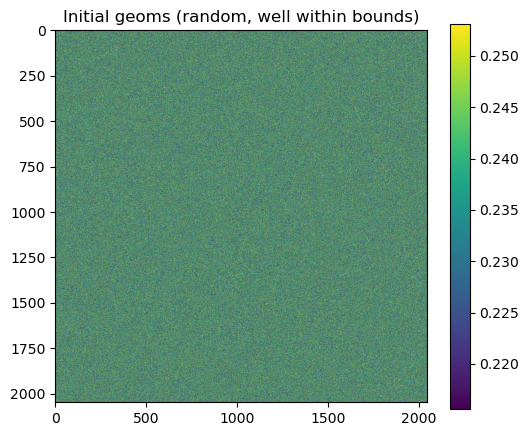

In [12]:
fig, ax = subplots(figsize=(6, 5))
im = ax.imshow(geoms)
ax.set_title("Initial geoms (random, well within bounds)")
fig.colorbar(im, ax=ax)
fig;

## Sample a random object

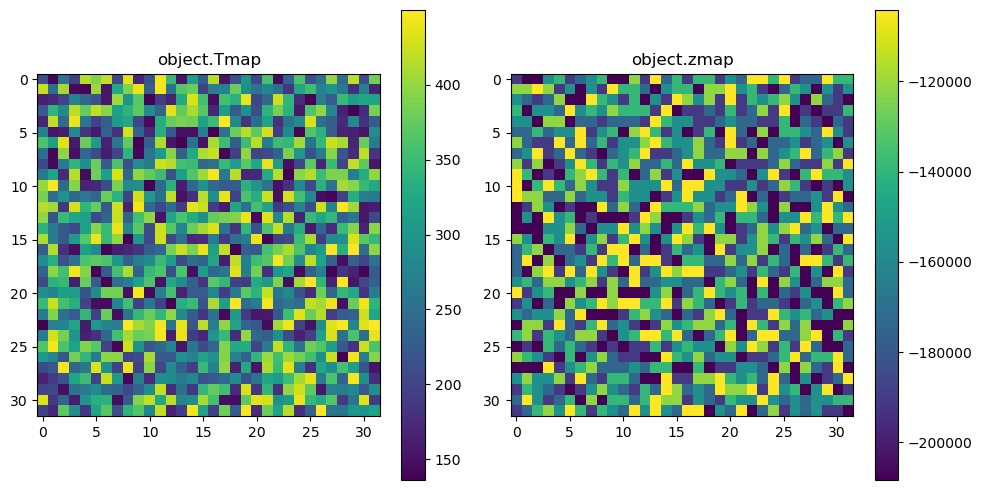

In [13]:
object = End2EndThermalImg.get_object(imghp)
noise = End2EndThermalImg.generate_noise(imghp)

fig, axes = subplots(1, 2; figsize=(10, 5))
im0 = axes[0].imshow(object.Tmap)
axes[0].set_title("object.Tmap")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(object.zmap)
axes[1].set_title("object.zmap")
fig.colorbar(im1, ax=axes[1])
fig.tight_layout()
fig;

## Image and noisy image

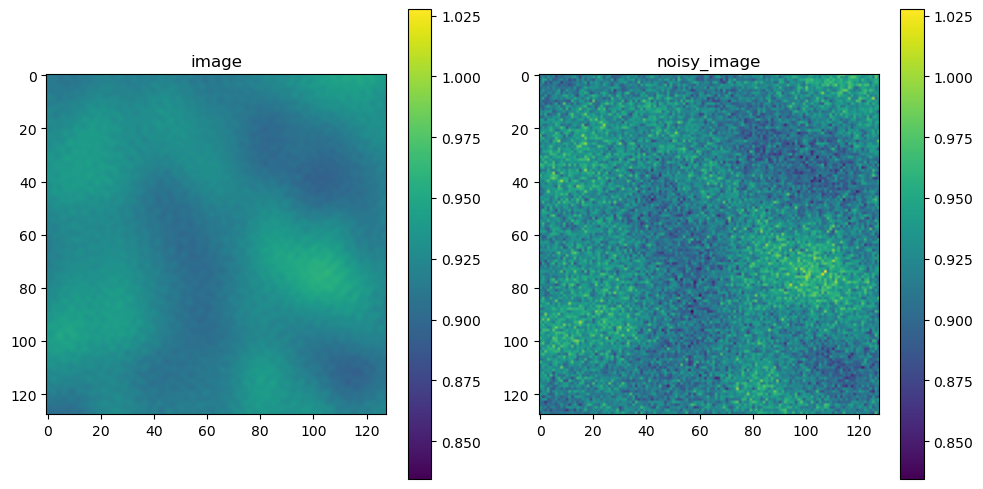

In [14]:
image = End2EndThermalImg.make_image_from_3D_distributed(object, weights, php, imghp)
noisy_image = End2EndThermalImg.make_noisy_image_from_3D_distributed(object, weights, noise, imghp.noise_type, php, imghp)

fig, axes = subplots(1, 2; figsize=(10, 5))
vlims = extrema(vcat(vec(image), vec(noisy_image)))

im0 = axes[0].imshow(image; vmin=vlims[1], vmax=vlims[2])
axes[0].set_title("image")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(noisy_image; vmin=vlims[1], vmax=vlims[2])
axes[1].set_title("noisy_image")
fig.colorbar(im1, ax=axes[1])
fig.tight_layout()
fig;

## Reconstruction

In [15]:
@time result = End2EndThermalImg.reconstruct_Tmap_and_zmap_distributed(noisy_image, weights, α, β, jhp; objective_scale = :auto)
object_opt = result.object_opt
println("return_value = ", result.return_value, "  iterations = ", length(result.objective_history))

 29.994624 seconds (25.65 M allocations: 1.513 GiB, 1.94% gc time, 3 lock conflicts, 18.18% compilation time)
return_value = SUCCESS  iterations = 111


## Reconstruction results

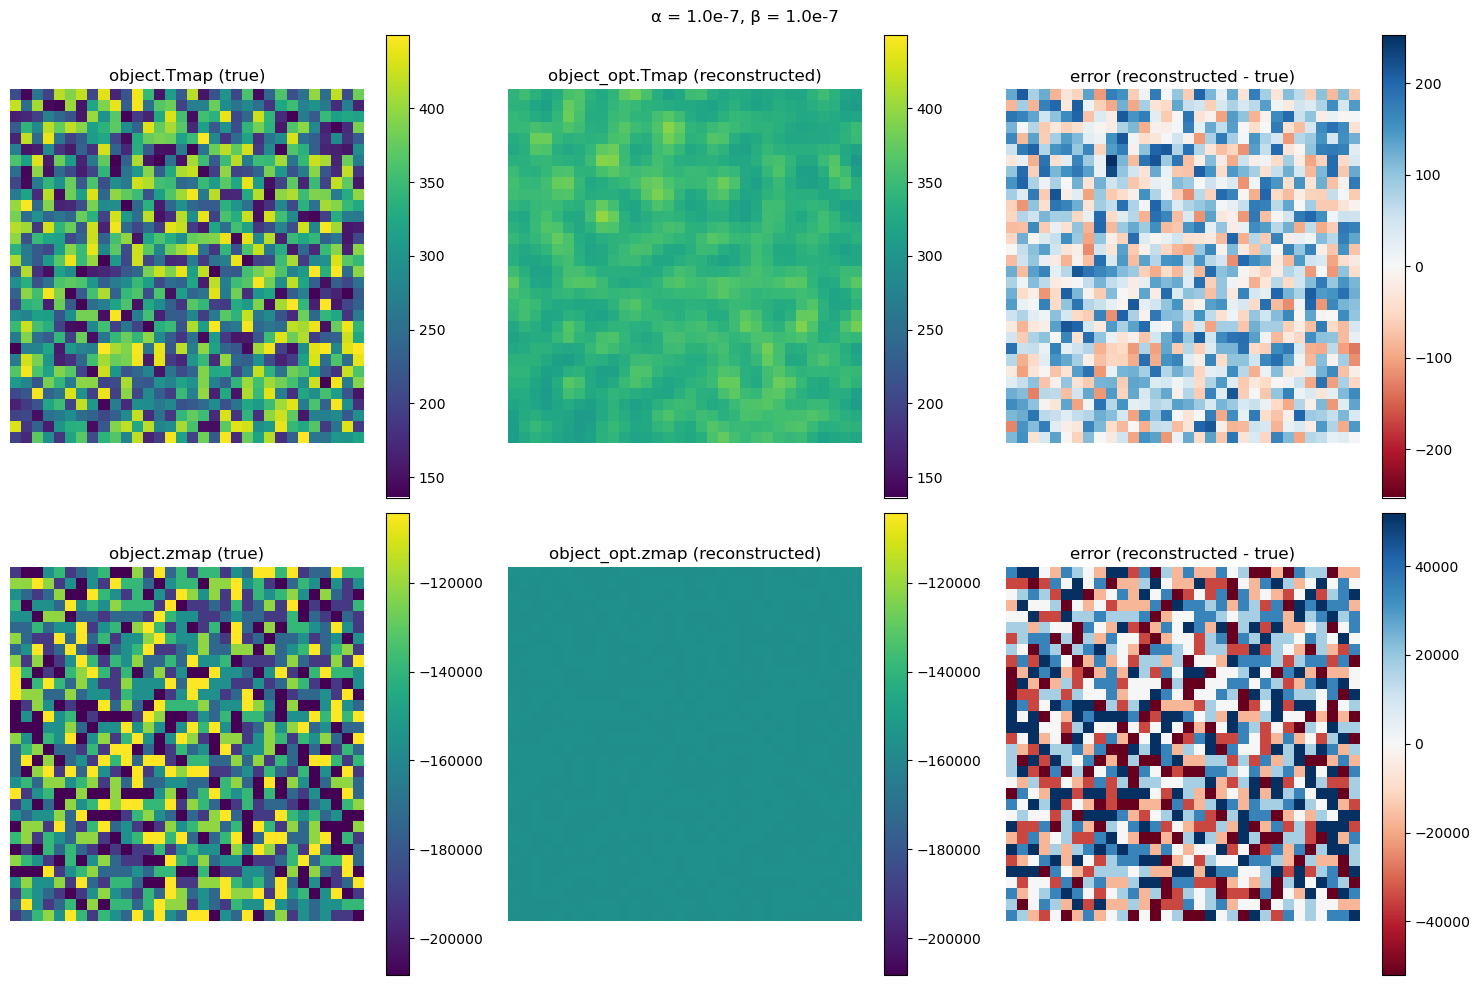

In [16]:
error_T = object_opt.Tmap .- object.Tmap
error_z = object_opt.zmap .- object.zmap

fig, axes = subplots(2, 3; figsize=(15, 10))

vlims_T = extrema(vcat(vec(object.Tmap), vec(object_opt.Tmap)))
im00 = axes[0,0].imshow(object.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,0].set_title("object.Tmap (true)")
fig.colorbar(im00, ax=axes[0,0])

im01 = axes[0,1].imshow(object_opt.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,1].set_title("object_opt.Tmap (reconstructed)")
fig.colorbar(im01, ax=axes[0,1])

elim_T = maximum(abs, error_T)
im02 = axes[0,2].imshow(error_T; cmap="RdBu", vmin=-elim_T, vmax=elim_T)
axes[0,2].set_title("error (reconstructed - true)")
fig.colorbar(im02, ax=axes[0,2])

vlims_z = extrema(vcat(vec(object.zmap), vec(object_opt.zmap)))
im10 = axes[1,0].imshow(object.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,0].set_title("object.zmap (true)")
fig.colorbar(im10, ax=axes[1,0])

im11 = axes[1,1].imshow(object_opt.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,1].set_title("object_opt.zmap (reconstructed)")
fig.colorbar(im11, ax=axes[1,1])

elim_z = maximum(abs, error_z)
im12 = axes[1,2].imshow(error_z; cmap="RdBu", vmin=-elim_z, vmax=elim_z)
axes[1,2].set_title("error (reconstructed - true)")
fig.colorbar(im12, ax=axes[1,2])

for ax in axes.flat
    ax.axis("off")
end
fig.suptitle("α = $α, β = $β")
fig.tight_layout()
fig;

## Reconstruction objective function history

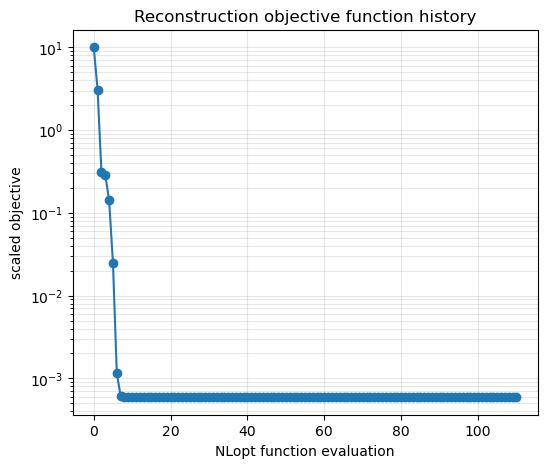

In [17]:
fig, ax = subplots(figsize=(6, 5))
ax.semilogy(result.objective_history .* result.objective_scale, marker="o")
ax.set_xlabel("NLopt function evaluation")
ax.set_ylabel("scaled objective")
ax.set_title("Reconstruction objective function history")
ax.grid(true, which="both", alpha=0.3)
fig;

## Adjoint solve and outer gradient

Solves the adjoint equation for `Λ`, then computes the full outer gradient (`[geoms; α; β]`) via
`outer_gradient_distributed` -- its `geoms` block is `Zygote.gradient` applied to
`Λ_dot_dFdo_distributed`, which is what the finite-difference check below compares against.

In [18]:
fftPSFs = let
    fftPSFs = Matrix{Matrix{ComplexF64}}(undef, length(freqs), length(PSF_zcoords))
    for p in workers()
        grid_inds, shard = remotecall_fetch(p) do
            (End2EndThermalImg._shard_grid_inds, End2EndThermalImg._fftPSFs_shard)
        end
        for idx in grid_inds
            iF, iZ = Tuple(idx)
            fftPSFs[iF, iZ] = shard[(iF, iZ)]
        end
    end
    fftPSFs
end

idx = End2EndThermalImg.get_free_and_active_indices(object_opt, imghp)
free_T, free_z = idx.free_T, idx.free_z
println("n_active_T = ", length(idx.active_T), " / ", imghp.objN^2, "   n_active_z = ", length(idx.active_z), " / ", imghp.objN^2)

b_T = vec(2 .* (object.Tmap .- object_opt.Tmap) ./ sum(abs2, object.Tmap))[free_T]
b_z = vec(2 .* (object.zmap .- object_opt.zmap) ./ sum(abs2, object.zmap))[free_z]
b = [b_T; b_z]
N_adjoint = length(free_T) + length(free_z)

A = End2EndThermalImg.build_hessian_operator_distributed(
    object, object_opt, fftPSFs, freqs, weights, driver_plans_PSF, noise, imghp.noise_type, α, β, php, imghp)
@time Λ, minres_hist = IterativeSolvers.minres!(zeros(N_adjoint), A, b; log = true)
println(minres_hist)

@time grad_full = End2EndThermalImg.outer_gradient_distributed(
    Λ, object, object_opt, geoms, fftPSFs, freqs, weights, driver_plans_PSF, noise, imghp.noise_type, rechp, php, imghp, PSF_scale)
grad = reshape(grad_full[1:end - 2], size(geoms))
println("norm(grad) = ", norm(grad))

n_active_T = 0 / 1024   n_active_z = 0 / 1024
  1.903764 seconds (4.84 M allocations: 322.810 MiB, 4.97% gc time, 1 lock conflict, 40.44% compilation time)
Converged after 26 iterations.
 69.676544 seconds (128.86 M allocations: 7.740 GiB, 2.77% gc time, 3 lock conflicts, 28.93% compilation time)
norm(grad) = 0.08904047712851736


## Formula-only checks with a fabricated, pinned `object_opt`

The real reconstruction above pinned neither `Tmap` nor `zmap` (`n_active_T = n_active_z = 0`), so
nothing above exercised the active-set (T/z-scatter) code at all. Rather than hunting for a real
reconstruction that happens to pin (finicky -- too-weak regularization tends to produce an
unstable, overfit reconstruction before it produces clean pinning), fabricate an `object_opt` with
a few `Tmap` *and* `zmap` pixels manually set to their bounds, and an arbitrary `Λ` of the matching
(compacted) length. This isn't a real reconstruction result -- it only needs the right shape to
exercise the scatter code -- so two different, complementary checks are worth separating:

1. **AD correctness**: does `Zygote.gradient` of `Λ_dot_dFdo_distributed` w.r.t. `geoms` match a
   genuine finite difference of its own value? This can only catch bugs in how Zygote
   differentiates the code (the `ignore_derivatives` scatter blocks, the custom rrule crossing the
   `pmap` boundary) -- it's blind to a bug in the formula's *value*, since both sides evaluate the
   same code.
2. **Value correctness**: does `Λ_dot_dFdo_distributed`'s own value (at a fixed `geoms`, no
   differentiation) match an independently-computed `dot(Λ, ∇_object[data_misfit])`, where
   `∇_object` comes from autodiffing the data-misfit term directly w.r.t. `object_opt` -- a
   completely separate code path from the hand-derived `term1`/`term2` formula? This is the check
   that can actually catch a wrong scatter (e.g. `Λ_T` landing at the wrong indices). Same approach
   the codebase already used historically to validate the original (z-only) formula (see the
   comment above `Λ_dot_dFdo`'s `return` statement in `src/backward.jl`).

In [19]:
Tmap_fab = copy(object_opt.Tmap)
zmap_fab = copy(object_opt.zmap)
Tmap_fab[1, 1] = End2EndThermalImg.T_LOWER_BOUND
Tmap_fab[2, 5] = End2EndThermalImg.T_LOWER_BOUND
Tmap_fab[7, 3] = End2EndThermalImg.T_LOWER_BOUND
zmap_fab[1, 2] = imghp.PSF_zlb
zmap_fab[4, 8] = imghp.PSF_zub
zmap_fab[9, 1] = imghp.PSF_zlb
object_opt_fab = (; Tmap = Tmap_fab, zmap = zmap_fab)

idx_fab = End2EndThermalImg.get_free_and_active_indices(object_opt_fab, imghp)
free_T_fab, free_z_fab = idx_fab.free_T, idx_fab.free_z
println("n_active_T = ", length(idx_fab.active_T), " / ", imghp.objN^2, "   n_active_z = ", length(idx_fab.active_z), " / ", imghp.objN^2)

N_fab = length(free_T_fab) + length(free_z_fab)
Λ_fab = randn(N_fab)
Λ_T_fab = Λ_fab[1:length(free_T_fab)]
Λ_z_fab = Λ_fab[length(free_T_fab) + 1:end];

n_active_T = 3 / 1024   n_active_z = 3 / 1024


### Test 1: AD correctness

In [22]:
# Zygote's gradient of Λ_dot_dFdo_distributed w.r.t. geoms vs a direct finite difference of its
# own value (recomputing real fftPSFs for the FD side; the Zygote side goes through
# get_fftPSFs_from_precomputed_distributed's custom rrule). geoms/fftPSFs here are the SAME ones
# from the real reconstruction above (unperturbed, already restored by that section).
function gather_fftPSFs()
    fftPSFs_g = Matrix{Matrix{ComplexF64}}(undef, length(freqs), length(PSF_zcoords))
    for p in workers()
        grid_inds, shard = remotecall_fetch(p) do
            (End2EndThermalImg._shard_grid_inds, End2EndThermalImg._fftPSFs_shard)
        end
        for idx in grid_inds
            iF, iZ = Tuple(idx)
            fftPSFs_g[iF, iZ] = shard[(iF, iZ)]
        end
    end
    fftPSFs_g
end

grad_fn_fab(g) = End2EndThermalImg.Λ_dot_dFdo_distributed(
    Λ_fab, object, object_opt_fab, g, fftPSFs, freqs, weights, driver_plans_PSF, noise, imghp.noise_type, php, imghp, PSF_scale)
grad_zygote_fab = Zygote.gradient(grad_fn_fab, geoms)[1]

function fd_value_fab(g)
    End2EndThermalImg.update_geoms_and_fftPSFs!(g, freqs, php, imghp, PSF_scale)
    fftPSFs_g = gather_fftPSFs()
    End2EndThermalImg.Λ_dot_dFdo_distributed(
        Λ_fab, object, object_opt_fab, g, fftPSFs_g, freqs, weights, driver_plans_PSF, noise, imghp.noise_type, php, imghp, PSF_scale)
end

h_fab = 1e-5
test_indices_fab = [(1, 1), (2, 2), (16, 16), (32, 1), (500, 500)]
println("=== Test 1: AD correctness (fabricated, pinned object_opt) ===")
for (i, j) in test_indices_fab
    gp = copy(geoms); gp[i, j] += h_fab
    gm = copy(geoms); gm[i, j] -= h_fab
    fd = (fd_value_fab(gp) - fd_value_fab(gm)) / (2h_fab)
    ad = grad_zygote_fab[i, j]
    rel_err = abs(fd - ad) / max(abs(fd), abs(ad), 1e-12)
    println("  ($i,$j): AD=$ad  FD=$fd  rel_err=$rel_err")
end

# restore resident fftPSFs to the original (unperturbed) geoms for later cells
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

=== Test 1: AD correctness (fabricated, pinned object_opt) ===
  (1,1): AD=4.445826490526892e-6  FD=4.445814029419015e-6  rel_err=2.8028776883618006e-6
  (2,2): AD=-7.579213645651357e-6  FD=-7.57922058447491e-6  rel_err=9.155062153689098e-7
  (16,16): AD=-1.0357962566726029e-6  FD=-1.0357987037523664e-6  rel_err=2.3625051418022657e-6
  (32,1): AD=-2.3152320477515895e-6  FD=-2.315267422225986e-6  rel_err=1.5278785533408095e-5
  (500,500): AD=-1.0492567865005053e-5  FD=-1.0492582497301227e-5  rel_err=1.3945371577510389e-6


### Test 2: value correctness

In [23]:
# Λ_dot_dFdo_distributed's own value (fixed geoms, no differentiation) vs an independently-
# computed dot(Λ, ∇_object[data_misfit]), autodiffed directly through the data-misfit term w.r.t.
# object_opt -- a completely separate code path from term1/term2. Both sides use the SAME
# (current, unperturbed) geoms/fftPSFs, so this needs no geoms perturbation at all.
plan_PSF = driver_plans_PSF[1]
v_true = End2EndThermalImg.make_noisy_image_from_3D(object, fftPSFs, weights, noise, imghp.noise_type, plan_PSF, php, imghp)

function data_misfit(object_opt_flat)
    object_x = End2EndThermalImg.unflatten_object(object_opt_flat)
    image_opt = End2EndThermalImg.make_image_from_3D(object_x, fftPSFs, weights, plan_PSF, php, imghp)
    sum((image_opt .- v_true).^2)
end

object_opt_fab_flat = End2EndThermalImg.flatten_object(object_opt_fab)
∇misfit = Zygote.gradient(data_misfit, object_opt_fab_flat)[1]
∇misfit_T = ∇misfit[1:imghp.objN^2][free_T_fab]
∇misfit_z = ∇misfit[imghp.objN^2 + 1:end][free_z_fab]

ground_truth_value = dot(Λ_T_fab, ∇misfit_T) + dot(Λ_z_fab, ∇misfit_z)

formula_value = End2EndThermalImg.Λ_dot_dFdo_distributed(
    Λ_fab, object, object_opt_fab, geoms, fftPSFs, freqs, weights, driver_plans_PSF, noise, imghp.noise_type, php, imghp, PSF_scale)

println("=== Test 2: value correctness (fabricated, pinned object_opt) ===")
println("formula value                        = ", formula_value)
println("independent ground truth (Λ·∇misfit) = ", ground_truth_value)
println("relative error = ", abs(formula_value - ground_truth_value) / abs(ground_truth_value))

=== Test 2: value correctness (fabricated, pinned object_opt) ===
formula value                        = -0.017450938948519044
independent ground truth (Λ·∇misfit) = -0.01745093894851905
relative error = 3.9762295452280453e-16


## Naive finite-difference check of `grad` against the outer bilevel objective

`F(geoms) = ||Tmap - Tmap_opt(geoms)||^2/||Tmap||^2 + ||zmap - zmap_opt(geoms)||^2/||zmap||^2`
(matching how `b` above was built -- T and z blocks each normalized by their own norm). Evaluating
`F` at a perturbed `geoms` requires a full reconstruction solve (`update_geoms_and_fftPSFs!` to
recompute resident fftPSFs, then `reconstruct_Tmap_and_zmap_distributed`) -- expensive, and
`geoms` is large, so this checks a *directional* derivative along one direction `v`, comparing
`dot(grad, v)` against a central difference of `F` along `v`, rather than reconstructing the full
gradient entrywise. `v` is a random direction, normalized by its own max-abs entry so that
`geoms .+ h .* v` deviates from `geoms` by at most `h` in any single entry (combined with the
margin `geoms` was generated with above, this keeps every perturbed entry safely inside
`[pillar_width_lb, pillar_width_ub]` for every `h` in the sweep below). `objective_function`
reuses the same `noise` realization every call (not re-randomized), and restores the resident
fftPSFs to the original `geoms` at the end.

Same caveat as the original version of this test (`2026-09-23-develop-pipeling.ipynb`): each
trial re-initializes the inner reconstruction from scratch (`rechp.object_init_type`) rather than
warm-starting from `object_opt` -- a non-convex inner reconstruction landing in a different local
optimum (or a different active set) at each perturbed `geoms` would show up here as noise in the
comparison, not necessarily a bug in `grad` itself.

In [24]:
println("extrema(geoms) = ", extrema(geoms), "  pillar_width bounds = (", php.pillar_width_lb, ", ", php.pillar_width_ub, ")")
println("baseline reconstruction: return_value = ", result.return_value, ", iterations = ", length(result.objective_history))

function objective_function(geoms_trial)
    # geoms was generated with a margin (see "Random geoms" above) specifically so this clamp
    # should never actually trigger for any h in the sweep below -- kept as a defensive no-op
    # rather than relying on that margin being exactly right.
    geoms_trial_clamped = clamp.(geoms_trial, php.pillar_width_lb, php.pillar_width_ub)
    End2EndThermalImg.update_geoms_and_fftPSFs!(geoms_trial_clamped, freqs, php, imghp, PSF_scale)
    noisy_image_trial = End2EndThermalImg.make_noisy_image_from_3D_distributed(object, weights, noise, imghp.noise_type, php, imghp)
    result_trial = End2EndThermalImg.reconstruct_Tmap_and_zmap_distributed(noisy_image_trial, weights, α, β, jhp; objective_scale = :auto)
    println("  geoms perturbation trial: return_value = ", result_trial.return_value, ", iterations = ", length(result_trial.objective_history))
    object_opt_trial = result_trial.object_opt
    norm(object.Tmap .- object_opt_trial.Tmap)^2 / norm(object.Tmap)^2 + norm(object.zmap .- object_opt_trial.zmap)^2 / norm(object.zmap)^2
end

extrema(geoms) = (0.21562500246726451, 0.2531249890933276)  pillar_width bounds = (0.1875, 0.28125000000000006)
baseline reconstruction: return_value = SUCCESS, iterations = 111


objective_function (generic function with 1 method)

In [25]:
v_geoms_random = randn(size(geoms))
v_geoms = v_geoms_random ./ maximum(abs, v_geoms_random)
dot_grad_v = dot(grad, v_geoms)
println("dot(grad, v) = ", dot_grad_v)

hs_geoms = [10.0^k for k in -2:-1:-8]
fds = Float64[]

for h in hs_geoms
    F_plus = objective_function(geoms .+ h .* v_geoms)
    F_minus = objective_function(geoms .- h .* v_geoms)
    fd = (F_plus - F_minus) / (2h)
    push!(fds, fd)
    rel_err = abs(dot_grad_v - fd) / abs(fd)
    println("h = ", h, "  fd = ", fd, "  relative error = ", rel_err)
end

# restore the resident fftPSFs to the original (unperturbed) geoms for later cells
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

dot(grad, v) = 0.023743396650818708
  geoms perturbation trial: return_value = SUCCESS, iterations = 108
  geoms perturbation trial: return_value = SUCCESS, iterations = 107
h = 0.010000000000000002  fd = 0.023348777263212935  relative error = 0.01690107294087359
  geoms perturbation trial: return_value = SUCCESS, iterations = 99
  geoms perturbation trial: return_value = SUCCESS, iterations = 114
h = 0.001  fd = 0.0233045793529979  relative error = 0.01882965966362134
  geoms perturbation trial: return_value = SUCCESS, iterations = 121
  geoms perturbation trial: return_value = SUCCESS, iterations = 119
h = 0.0001  fd = 0.023164896942595714  relative error = 0.0249731181475384
  geoms perturbation trial: return_value = SUCCESS, iterations = 113
  geoms perturbation trial: return_value = SUCCESS, iterations = 103
h = 1.0e-5  fd = 0.0241306041884326  relative error = 0.016046325843739367
  geoms perturbation trial: return_value = SUCCESS, iterations = 114
  geoms perturbation trial: ret

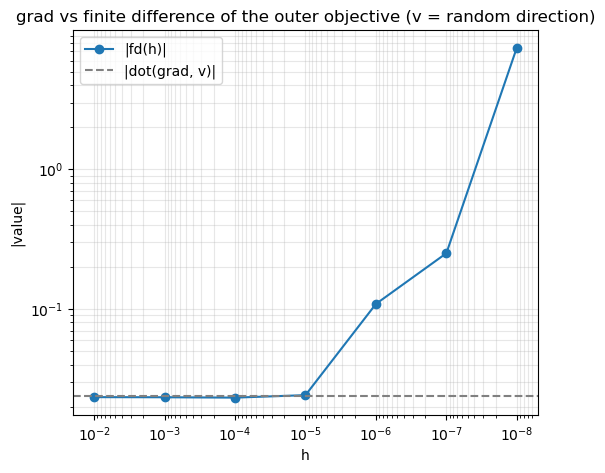

In [26]:
fig, ax = subplots(figsize=(6, 5))
ax.loglog(hs_geoms, abs.(fds), marker="o", label="|fd(h)|")
ax.axhline(abs(dot_grad_v), color="gray", linestyle="--", label="|dot(grad, v)|")
ax.invert_xaxis()
ax.set_xlabel("h")
ax.set_ylabel("|value|")
ax.legend()
ax.set_title("grad vs finite difference of the outer objective (v = random direction)")
ax.grid(true, which="both", alpha=0.3)
fig;

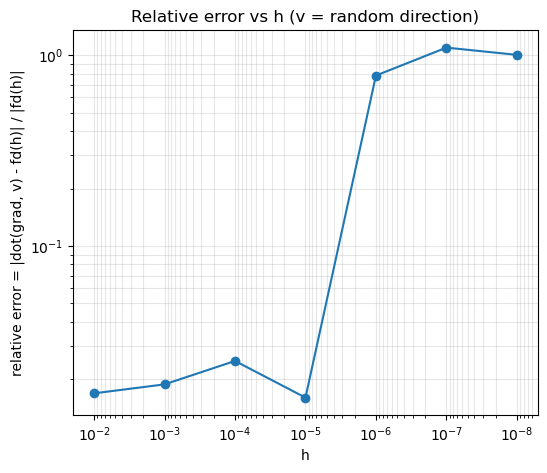

In [27]:
rel_errs = abs.(dot_grad_v .- fds) ./ abs.(fds)

fig, ax = subplots(figsize=(6, 5))
ax.loglog(hs_geoms, rel_errs, marker="o")
ax.invert_xaxis()
ax.set_xlabel("h")
ax.set_ylabel("relative error = |dot(grad, v) - fd(h)| / |fd(h)|")
ax.set_title("Relative error vs h (v = random direction)")
ax.grid(true, which="both", alpha=0.3)
fig;